In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn import metrics
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn import preprocessing

import os
os.chdir("D:/gus6e/Documents")

In [7]:
col_names = ["Age", "Sex", "BP", "Cholesterol", "Na_to_K", "Drug"]
pima = pd.read_csv("drugs.csv", header = None, names = col_names)
df = pima.iloc[1:,:]
df

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
1,23,F,HIGH,HIGH,25.355,drugY
2,47,M,LOW,HIGH,13.093,drugC
3,47,M,LOW,HIGH,10.114,drugC
4,28,F,NORMAL,HIGH,7.798,drugX
5,61,F,LOW,HIGH,18.043,drugY
...,...,...,...,...,...,...
196,56,F,LOW,HIGH,11.567,drugC
197,16,M,LOW,HIGH,12.006,drugC
198,52,M,NORMAL,HIGH,9.894,drugX
199,23,M,NORMAL,NORMAL,14.02,drugX


In [8]:
pima = preprocessing.LabelEncoder()
df["Sex"] = pima.fit_transform(df["Sex"])
df["BP"] = pima.fit_transform(df["BP"])
df["Cholesterol"] = pima.fit_transform(df["Cholesterol"])

df["label"] = df["Drug"].map({"drugA":0, "drugB":0, "drugC":0, "drugX":1, "drugY":1})
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug,label
1,23,0,0,0,25.355,drugY,1
2,47,1,1,0,13.093,drugC,0
3,47,1,1,0,10.114,drugC,0
4,28,0,2,0,7.798,drugX,1
5,61,0,1,0,18.043,drugY,1


In [10]:
# Selección de las características
feature_cols = ["Age", "Sex", "BP", "Cholesterol", "Na_to_K"]
x = df[feature_cols]
y = df.label

In [11]:
# Creación de las bases de entrenamiento de prueba
x_train, x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2, random_state = 1)

In [12]:
# sag: Stochastic Average Gradient
# newton-cg: Newton
# liblinear: Library for large linear Classification (Algoritmo Coordinate Descent)
# saga: Variante del método sag
# lbfgs: Limited-memory Broyden-Fletcher-Goldfarb-Shanno Algorithm

# Regresión logísitca con solucionador (Solver): sag

In [13]:
model = LogisticRegression(solver="sag")
clf = model.fit(x_train,y_train)

In [14]:
# Predicción de etiquetas de clase sobre datos de prueba
y_pred = model.predict(x_test)

# Impresión de coeficientes de la regresión de puntajes
print("Intercepto (Beta 0)",clf.intercept_)
print("Pesos de cada variable (Beta1, Beta2, ... , Beta5)",clf.coef_)

Intercepto (Beta 0) [-0.31195197]
Pesos de cada variable (Beta1, Beta2, ... , Beta5) [[-0.03748102 -0.16242261  1.03069788  0.20122708  0.16022598]]


In [15]:
# Evaluación de la precisión del modelo
score = model.score(x_test, y_test)
print("Score de precisión: ", score)

Score de precisión:  0.9


In [16]:
# Reporte de clasificación
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.60      0.75        10
           1       0.88      1.00      0.94        30

    accuracy                           0.90        40
   macro avg       0.94      0.80      0.84        40
weighted avg       0.91      0.90      0.89        40



# Regresión logística con solucionador (Solver): newton-cg

In [26]:
model = LogisticRegression(solver = "newton-cg")
clf = model.fit(x_train,y_train)

y_pred = model.predict(x_test)

print("Intercepto (Beta 0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("____________________________________________________________")
score = model.score(x_test,y_test)
print("Precisión global:", score)
print("____________________________________________________________")
print(classification_report(y_test,y_pred))

Intercepto (Beta 0): [-11.15244637]
Pesos (Betas): [[0.00660794 0.1483032  3.33609316 2.07244718 0.6378735 ]]
____________________________________________________________
Precisión global: 0.975
____________________________________________________________
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



# Regresión logística con solucionador (Solver): liblinear

In [18]:
model = LogisticRegression(solver = "liblinear")
clf = model.fit(x_train,y_train)

y_pred = model.predict(x_test)

print("Intercepto (Beta 0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("____________________________________________________________")
score = model.score(x_test,y_test)
print("Precisión global:", score)
print("____________________________________________________________")
print(classification_report(y_test,y_pred))

Intercepto (Beta 0): [-3.34051275]
Pesos (Betas): [[-0.02834219 -0.26053256  2.06969328  1.09570978  0.27510142]]
____________________________________________________________
Precisión global: 0.975
____________________________________________________________
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



# Regresión logística con solucionador (Solver): saga

In [19]:
model = LogisticRegression(solver = "saga")
clf = model.fit(x_train,y_train)

y_pred = model.predict(x_test)

print("Intercepto (Beta 0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("____________________________________________________________")
score = model.score(x_test,y_test)
print("Precisión global:", score)
print("____________________________________________________________")
print(classification_report(y_test,y_pred))

Intercepto (Beta 0): [-0.14681563]
Pesos (Betas): [[-0.03375957 -0.09257693  0.66067608  0.10531952  0.15456863]]
____________________________________________________________
Precisión global: 0.875
____________________________________________________________
              precision    recall  f1-score   support

           0       0.86      0.60      0.71        10
           1       0.88      0.97      0.92        30

    accuracy                           0.88        40
   macro avg       0.87      0.78      0.81        40
weighted avg       0.87      0.88      0.87        40



# Regresión logística con solucionador (Solver): lbfgs

In [20]:
model = LogisticRegression(solver = "lbfgs")
clf = model.fit(x_train,y_train)

y_pred = model.predict(x_test)

print("Intercepto (Beta 0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("____________________________________________________________")
score = model.score(x_test,y_test)
print("Precisión global:", score)
print("____________________________________________________________")
print(classification_report(y_test,y_pred))

Intercepto (Beta 0): [-11.16791614]
Pesos (Betas): [[0.00667297 0.14894912 3.33863745 2.07461152 0.63862512]]
____________________________________________________________
Precisión global: 0.975
____________________________________________________________
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



In [21]:
# Predicción de probabilidades para casos particulares
y_pred_probs = clf.predict_proba(x_test)[:,1]
y_pred_probs[0:5]

array([0.9898257 , 0.99974436, 0.99355295, 0.67717001, 0.99999695])

In [22]:
y_test[0:5]

59     1
41     1
35     1
103    0
185    1
Name: label, dtype: int64

In [23]:
y_test = y_test.to_numpy()
y_test[0:5]

array([1, 1, 1, 0, 1])

In [27]:
import numpy as np
y_pred_probs = np.round(y_pred_probs,0)
y_pred_probs[0:5]

array([1., 1., 1., 1., 1.])

In [28]:
# Graficación de la curva ROC y cálculo del área bajo la curva
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
# fpr = false positive rate
# tpr = true positive rate
# tresholds = límites para valores de p
fpr,tpr, tresholds = roc_curve(y_test,y_pred_probs)
auc = roc_auc_score(y_test,y_pred_probs)
print("Área bajo la curva (AUC):",auc)

Área bajo la curva (AUC): 0.9500000000000001


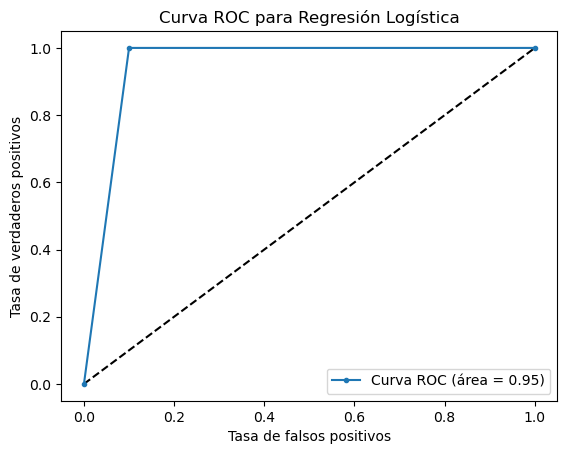

In [29]:
plt.plot([0,1],[0,1], "k--")
plt.plot(fpr,tpr,marker= ".", label = "Curva ROC (área = %0.2f)" % auc)
plt.xlabel("Tasa de falsos positivos") #False positive rate
plt.ylabel("Tasa de verdaderos positivos") #True positive rate
plt.legend(loc = "lower right")
plt.title("Curva ROC para Regresión Logística")
plt.show()